# Powerful initial forecasts

## 1. The Path-to-Title Helper

In [7]:
import os

def suptitle_from_path(npz_path, split_name="TEST"):
    """
    Parses the folder structure to create a standardized suptitle.
    Expected path: ...\dataset\token_style\model\Lx_Ty\seed_z\...
    """
    # Normalize path for Windows/Linux
    path_parts = npz_path.replace('\\', '/').split('/')
    
    # Based on your tree:
    # [-7] = dataset (ETTh1)
    # [-6] = token_style (variate)
    # [-5] = model (gru)
    # [-4] = L96_T96
    # [-3] = seed_42
    
    try:
        dataset = path_parts[-7]
        style   = path_parts[-6]
        model   = path_parts[-5]
        dims    = path_parts[-4].replace('_', ' ') # L96 T96
        seed    = path_parts[-3] # seed_42
        
        return f"{split_name.upper()} FORECASTS | {dataset} | {model} | {style} | {seed} | {dims}"
    except IndexError:
        return f"FORECASTS | {os.path.basename(npz_path)}"

# --- Usage ---
# npz_path = r'runs_debug\ETTh1\variate\gru\L96_T96\seed_42\2026-03-14_22-44\test\test_outputs.npz'
npz_path = r'runs_debug\ETTh1\variate\mamba\L96_T96\seed_42\2026-03-14_22-45\test\test_outputs.npz'

generated_title = suptitle_from_path(npz_path)
print(f"Generated: {generated_title}")

Generated: TEST FORECASTS | variate | L96_T96 | mamba | 2026-03-14_22-45 | seed 42


## 2. Full Integration in tmp.ipynb

[plot_tmp] Loaded NPZ : Y(2422, 96, 7), P(2422, 96, 7)
[plot_tmp] Available windows: N=2422 | horizon T=96 | channels V=7
[plot_tmp] Using random window_indices (k=1): [1880]


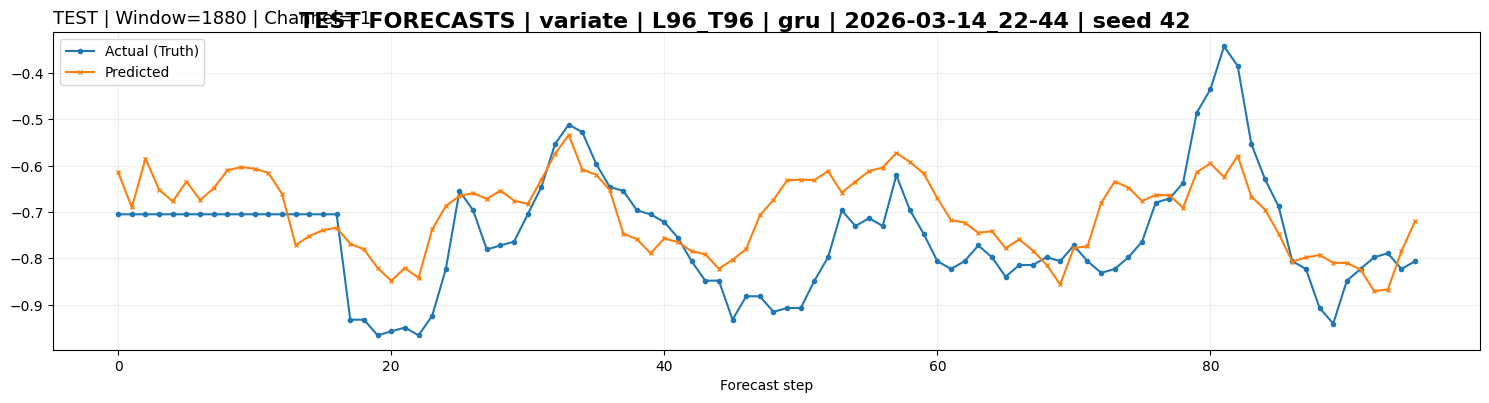

In [6]:
from utils.visualization_tmp import plot_forecasts_from_npz

# Path to the file
sample_npz = r'runs_debug\ETTh1\variate\gru\L96_T96\seed_42\2026-03-14_22-44\test\test_outputs.npz'

# Generate title
my_suptitle = suptitle_from_path(sample_npz)

# Plot
plot_forecasts_from_npz(
    npz_path=sample_npz,
    window_indices="random", 
    channel_idx=-1,
    save_dir=None,
    show=True,
    num_random=1,
    seed=10,                  
    suptitle=my_suptitle,
)

### test same etth preds by an other model

[plot_tmp] Loaded NPZ : Y(2422, 96, 7), P(2422, 96, 7)
[plot_tmp] Available windows: N=2422 | horizon T=96 | channels V=7
[plot_tmp] Using random window_indices (k=1): [1880]


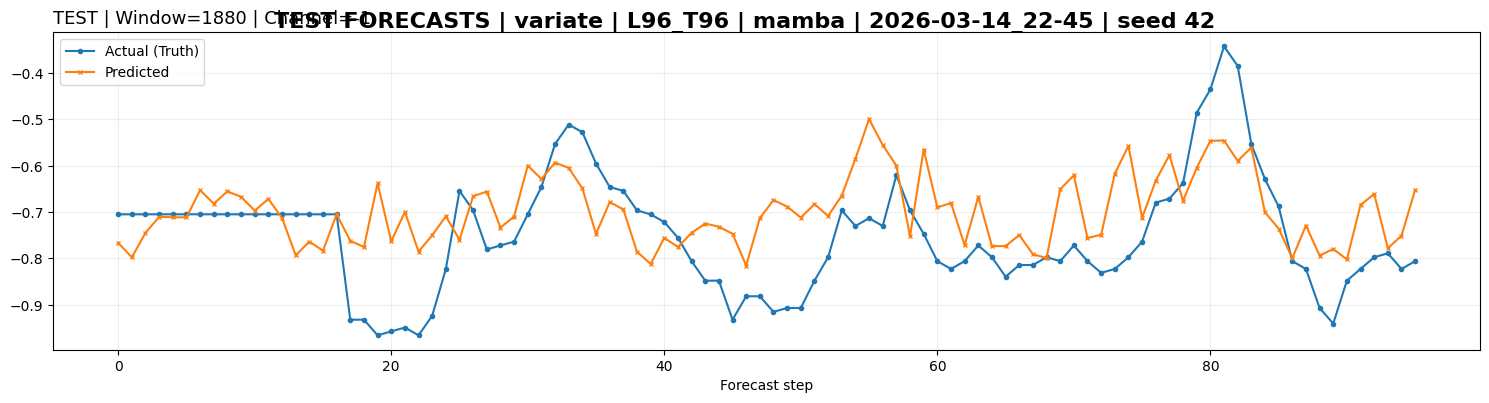

In [9]:
from utils.visualization_tmp import plot_forecasts_from_npz

# Path to the file
sample_npz = r'runs_debug\ETTh1\variate\mamba\L96_T96\seed_42\2026-03-14_22-45\test\test_outputs.npz'
                

# Generate title
my_suptitle = suptitle_from_path(sample_npz)

# Plot
plot_forecasts_from_npz(
    npz_path=sample_npz,
    window_indices="random", 
    channel_idx=-1,
    save_dir=None,
    show=True,
    num_random=1,
    seed=10,                  
    suptitle=my_suptitle,
)

# Simpler paper forecasts

## ECL forecast grid

[forecast_grid] available windows: N=3755 | horizon T=96 | channels V=321


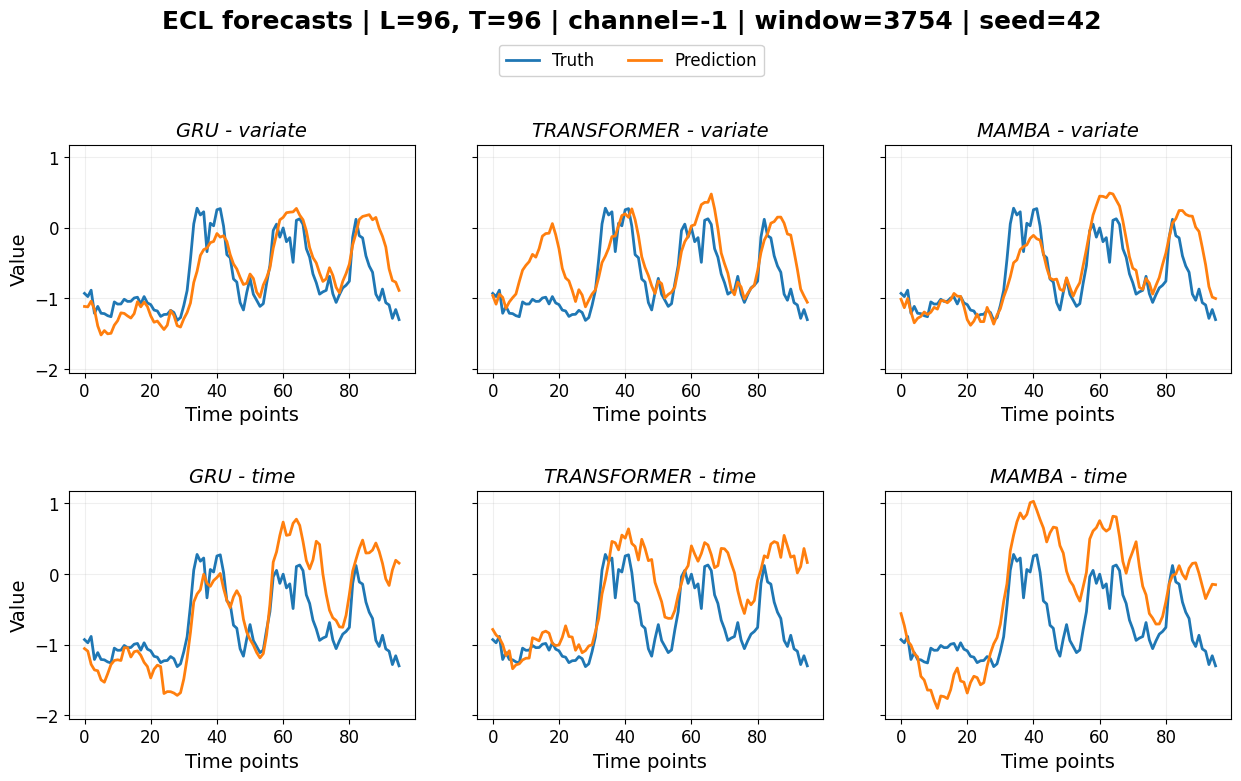

In [1]:
import importlib
import windows11.utils.forecasts_visual as fv

importlib.reload(fv)

fv.plot_ecl_forecast_grid(
    runs_debug_root=r"runs_debug",
    window_idx=3754,
    channel_idx=-1,
    save_path=None,
    show=True,
    verbose=True,
)

## ETTh1 forecast grid

[forecast_grid] available windows: N=2422 | horizon T=96 | channels V=7


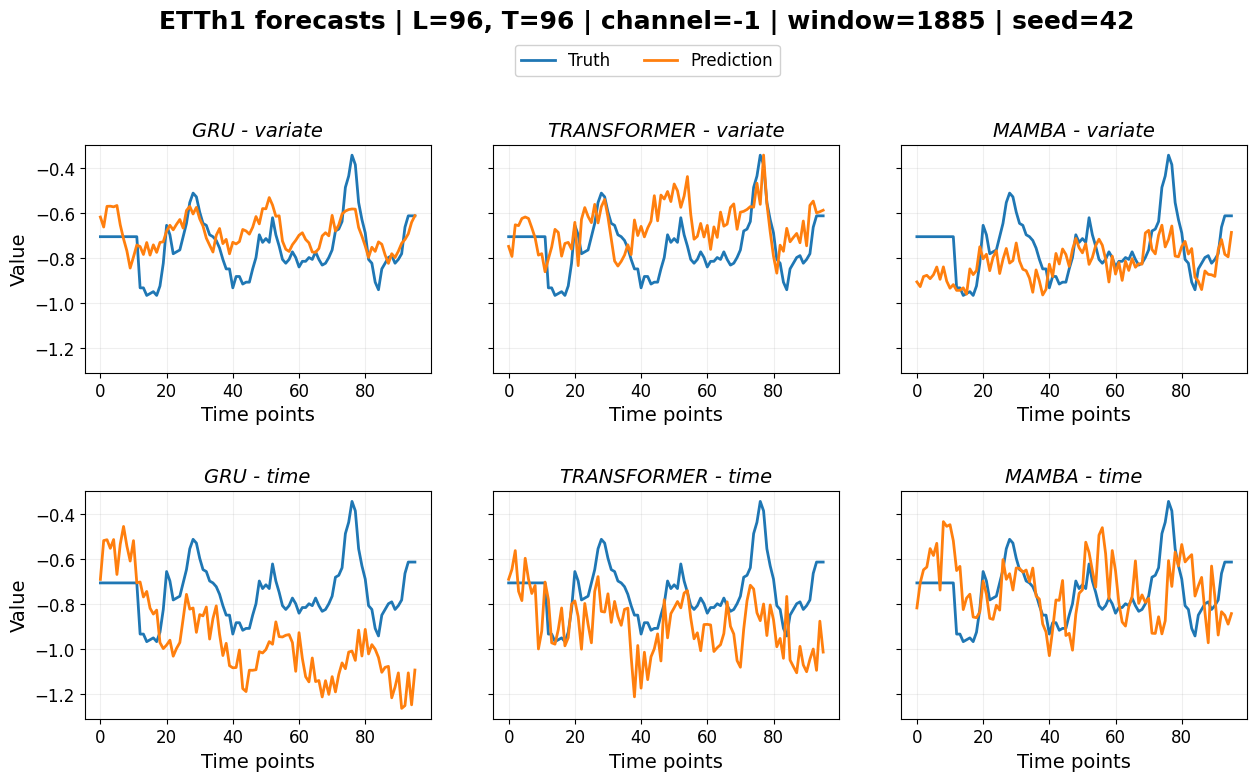

In [4]:
import importlib
import windows11.utils.forecasts_visual as fv

importlib.reload(fv)

fv.plot_etth1_forecast_grid(
    runs_debug_root=r"runs_debug",
    window_idx=1885,
    channel_idx=-1,
    save_path=None,
    show=True,
    verbose=True,
)

# save all forecast grids

In [2]:
import importlib
import windows11.utils.forecasts_visual as fv

importlib.reload(fv)

fv.save_all_forecast_grids(
    runs_debug_root=r"runs_debug",
    out_dir=r"windows11/figures",
    ecl_window_idx=3754,
    ecl_channel_idx=-1,
    etth1_window_idx=1885,
    etth1_channel_idx=-1,
    show=False,
    verbose=True,
)

[forecast_grid] available windows: N=3755 | horizon T=96 | channels V=321
[forecast_grid] available windows: N=2422 | horizon T=96 | channels V=7
